# Chandra — Document Intelligence & OCR Layout Analysis Pipeline

Pipeline phân tích layout tài liệu bằng mô hình **Chandra** (phát triển bởi nhóm nghiên cứu **Datalab**).

### Kiến trúc Document Understanding
- **Full-Page Decoding**: Giải mã bố cục văn bản, biểu đồ, cấu trúc bảng biểu phức tạp và công thức toán học bảo toàn vị trí không gian.
- **End-to-End Layout Parsing**: Chandra xuất cấu trúc layout có bounding box thông qua cơ chế prompt có cấu trúc (JSON/HTML blocks).
- **Taxonomy Mapping**: Tự động chuẩn hóa các block types của Chandra về 11 danh mục chuẩn của **DocLayNet** (`Caption`, `Footnote`, `Formula`, `List-item`, `Page-footer`, `Page-header`, `Picture`, `Section-header`, `Table`, `Text`, `Title`) và 5 danh mục của **PubLayNet**.

In [1]:
from pathlib import Path
import subprocess
import sys

# Khởi tạo đường dẫn gốc project
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "chandra"
DATASET = "doclaynet_test"
SPLIT = "test"
IOU_THRESHOLD = 0.5
LIMIT = 150  # gioi han do VLM sinh cham tren GPU 8GB (~110s/anh)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 10

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")


Project: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261
Pipeline: chandra | doclaynet/train | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\outputs\predictions\chandra\doclaynet
Figures: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\outputs\reports\chandra_doclaynet


## 0. Kiểm tra mã nguồn, môi trường và tự động tải trọng số (Setup & Auto-Download)

Tế bào này kiểm tra sự tồn tại của thư viện phụ thuộc (`transformers`, `accelerate`), bộ trọng số chính thức của `Chandra` từ Hugging Face Hub (`datalab-to/chandra-ocr-2`), và tập dữ liệu. Nếu chưa có file trọng số, hệ thống sẽ tự động tải về thư mục `methods/chandra/weights/` để người dùng có thể chạy trực tiếp toàn bộ notebook.

In [2]:
import subprocess
import sys
from pathlib import Path

# 1. Kiểm tra thư viện transformers
try:
    import transformers
    print("[OK] Thư viện transformers đã sẵn sàng.")
except ImportError:
    print("[Setup] Đang cài đặt thư viện transformers...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "transformers", "accelerate"])
    import transformers

# 2. Kiểm tra và tự động tải trọng số pre-trained nếu chưa có
weights_dir = ROOT / "methods" / "chandra" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)
has_weights = (weights_dir / "config.json").exists() and any(weights_dir.glob("*.safetensors"))

if not has_weights:
    print("[Setup] Chưa có file trọng số Chandra cục bộ. Đang tự động tải về từ Hugging Face (datalab-to/chandra-ocr-2)...\n")
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id="datalab-to/chandra-ocr-2", local_dir=str(weights_dir), ignore_patterns=["*.msgpack", "*.h5", "*.ot"])
    print("[OK] Tải trọng số Chandra thành công!")
else:
    print(f"[OK] Trọng số Chandra đã sẵn sàng tại: {weights_dir}")

# 3. Kiểm tra tập dữ liệu DocLayNet
images_dir = ROOT / "datasets" / DATASET / "processed" / "images"
if not images_dir.is_dir() or not any(images_dir.glob("*.png")):
    print(f"[Cảnh báo] Chưa tìm thấy ảnh tại: {images_dir}. Hãy đảm bảo đã chuẩn bị dataset trước khi chạy inference.")
else:
    num_images = len(list(images_dir.glob("*.png")))
    print(f"[OK] Tập dữ liệu {DATASET} sẵn sàng ({num_images} ảnh).")


c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Thư viện transformers đã sẵn sàng.
[Setup] Chưa có file trọng số Chandra cục bộ. Đang tự động tải về từ Hugging Face (datalab-to/chandra-ocr-2)...



Fetching 17 files: 100%|██████████| 17/17 [15:36<00:00, 55.07s/it]

[OK] Tải trọng số Chandra thành công!
[OK] Tập dữ liệu doclaynet sẵn sàng (250 ảnh).


## 1. Prediction

Chạy layout detection bằng script `methods/chandra/src/run_inference.py`. Script nạp model Chandra, gửi prompt trích xuất layout và sinh kết quả dự đoán ra `outputs/predictions/chandra/<dataset>/`.

In [3]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
cmd = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
]
if not FORCE_INFERENCE:
    cmd.append("--skip-existing")
else:
    cmd.append("--force")

print(f"Running: {' '.join(cmd)}")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])


Running: c:\Users\ACER\AppData\Local\Programs\Python\Python312\python.exe D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\methods\chandra\src\run_inference.py --dataset doclaynet --limit 5 --skip-existing
[chandra] 5 image(s) to predict from D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\datasets\doclaynet\processed\images (device: cuda) (existing predictions skipped)
[chandra] Sử dụng trọng số có sẵn tại: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\methods\chandra\weights
[chandra] Khởi tạo mô hình từ: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\methods\chandra\weights (device=cuda)

Errors / Warnings: e 277, in main
    model, processor = load_chandra_model(model_target, device=args.device)
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\methods\chandra\src\run_inference.py", line 102, in load_chandra_model
    raise RuntimeError(f"Không thể khởi tạo mô hình Chandra từ {model_path_or_id}")
Runtime

## 2. Metrics and Evaluation Chart

Đánh giá các dự đoán layout theo chuẩn COCO và benchmark DocLayNet:
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP**: Tính toán mAP@[0.5:0.95] và mAP@0.5.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:
Evaluation: chandra on doclaynet/train | 0 images | GT=0 boxes | Predictions=0 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.000  Recall=0.000  F1=0.000  TP=0 FP=0 FN=0  mean IoU=0.000
Macro (mean across 0 ground-truth classes): Precision=0.000  Recall=0.000  F1=0.000
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Caption                  0       0      0      0      0    0.000    0.000    0.000
Footnote                 0       0      0      0      0    0.000    0.000    0.000
Formula                  0       0      0      0      0    0.000    0.000    0.000
List-item                0       0      0      0      0    0.000    0.000    0.000
Page-footer              0       0      0      0      0    0.000    0.000    0.000
Page-header              0       0      0      0      0    0.000    0.000    0.000
Picture                  0       0      0      0      0    0.000    0.000    0.000
Section-header    

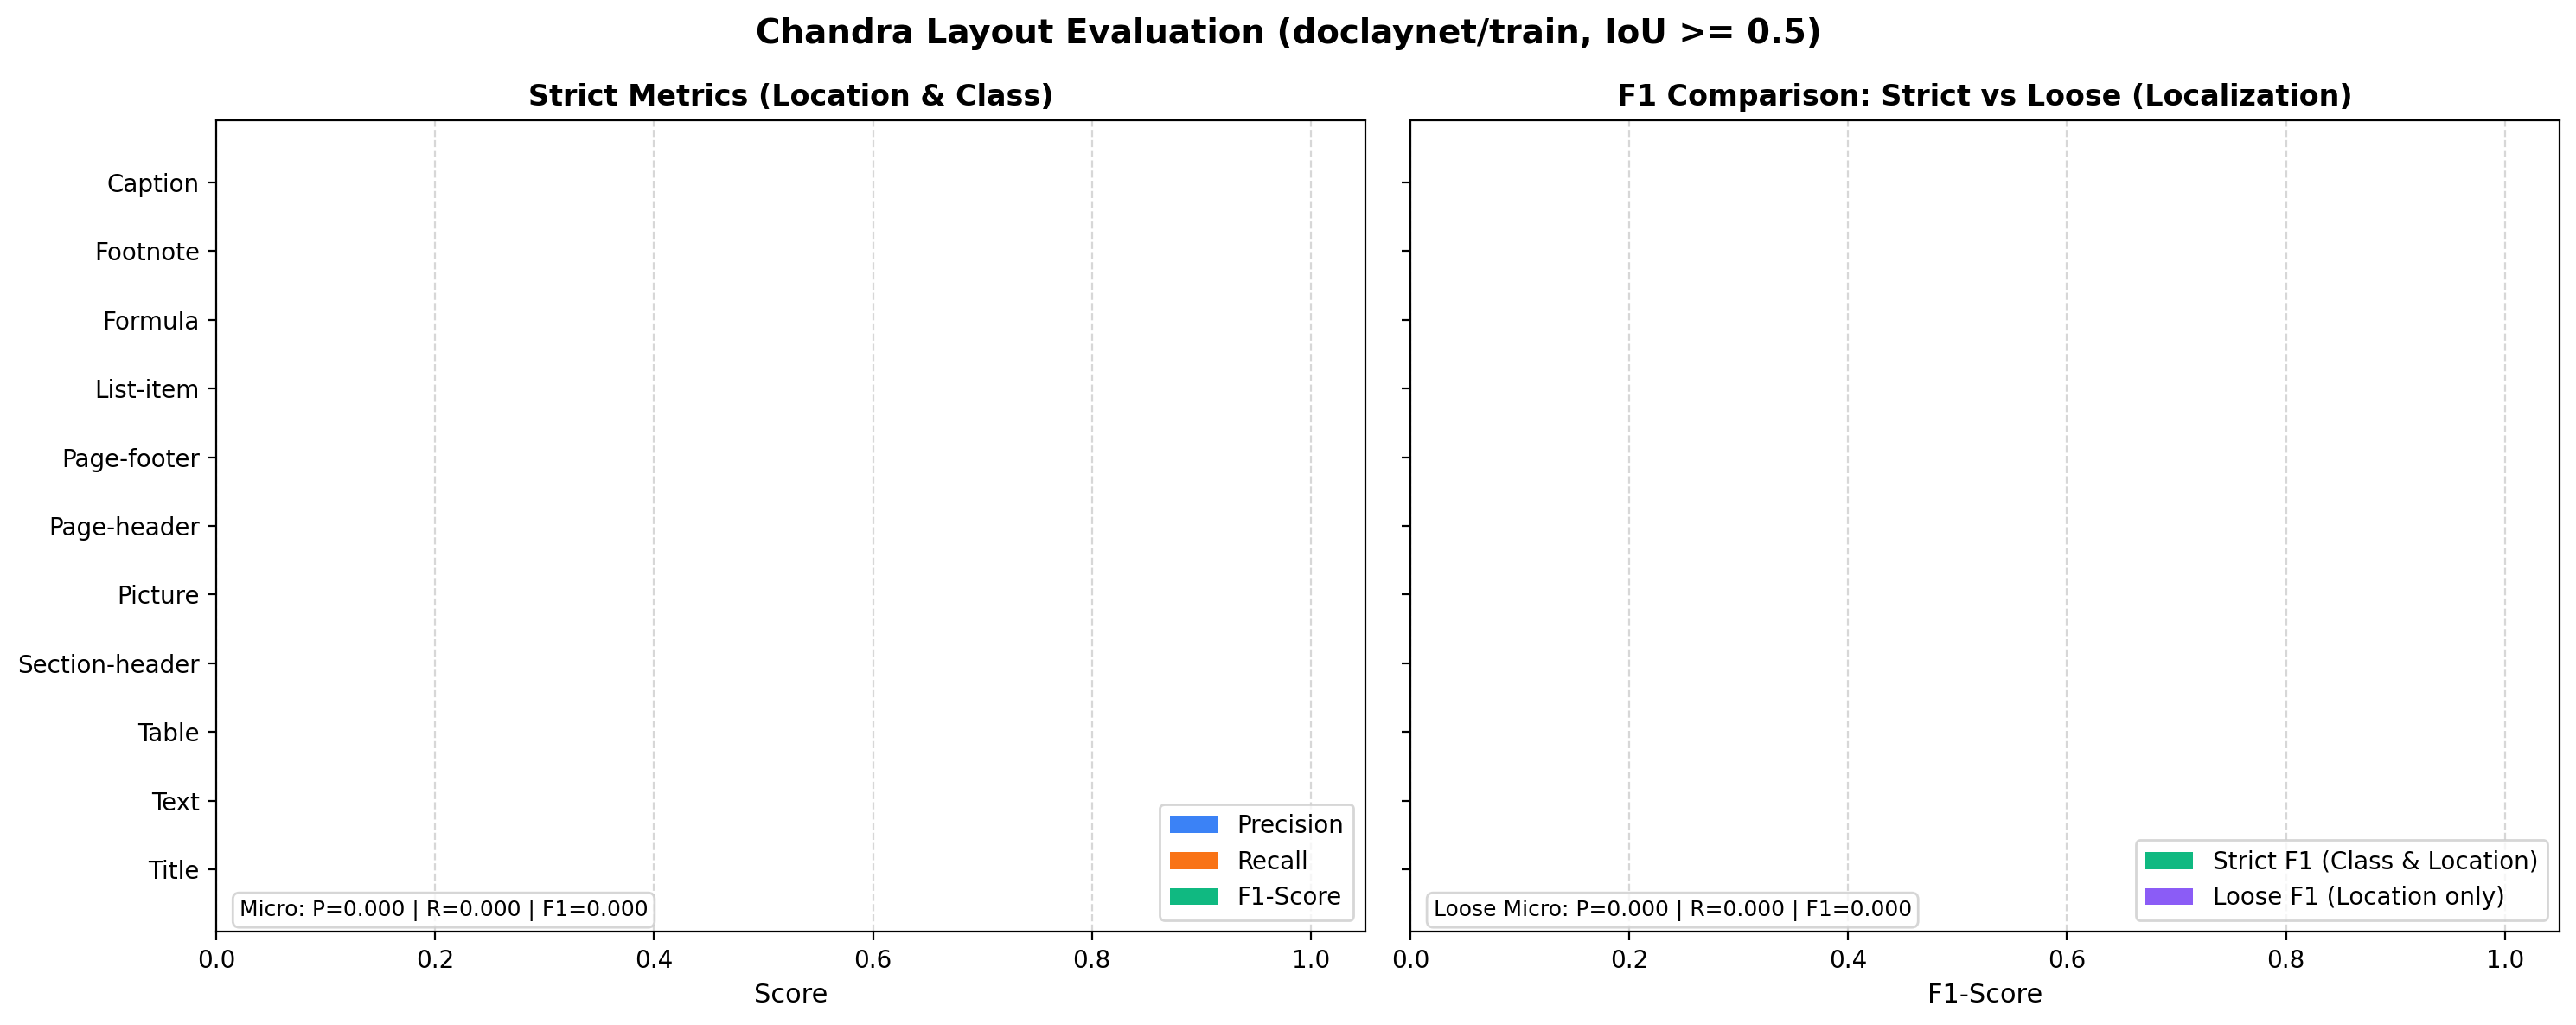

In [4]:
eval_script = ROOT / "scripts" / "evaluate_predictions.py"
chart_path = FIGURES_DIR / "metrics_chart.png"
chart_path.parent.mkdir(parents=True, exist_ok=True)

cmd = [
    sys.executable,
    str(eval_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--allow-incomplete",
    "--loose",
    "--plot", str(chart_path),
]

print("Running evaluation:")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

if chart_path.exists():
    from IPython.display import Image, display
    print(f"\nEvaluation Chart ({chart_path}):")
    display(Image(filename=str(chart_path)))


## 3. Ground Truth vs. Prediction Examples

Vẽ bounding box Ground Truth (bên trái) đối chiếu với dự đoán của Chandra (bên phải) cạnh nhau trên cùng một ảnh để trực quan hóa chất lượng nhận diện layout.

In [5]:
viz_script = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
cmd = [
    sys.executable,
    str(viz_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]

print(f"Running: {' '.join(cmd)}")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

import glob
from IPython.display import Image, display

fig_files = sorted(FIGURES_DIR.glob("*.png"))
sample_files = [f for f in fig_files if f.name != "metrics_chart.png"][:4]
print(f"\nHiển thị {len(sample_files)} ảnh mẫu (Ground Truth vs {METHOD}):")
for f in sample_files:
    print(f"Ảnh: {f.name}")
    display(Image(filename=str(f)))


Running: c:\Users\ACER\AppData\Local\Programs\Python\Python312\python.exe D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\visualization\scripts\visualize_predictions.py --method chandra --dataset doclaynet --split train --limit 20 --output-dir D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\outputs\reports\chandra_doclaynet
[viz] Ve 0 anh (chandra vs ground truth) tu D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\visualization\scripts\..\..\outputs\predictions\chandra\doclaynet
[viz] Xong. Anh luu tai D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\outputs\reports\chandra_doclaynet


Hiển thị 0 ảnh mẫu (Ground Truth vs chandra):
